In [1]:
import numpy as np
import scipy.stats

import matplotlib.pyplot as plt
from functools import partial
from tqdm import tqdm # gives a progress bar

In [2]:
title = "# Sampling 1: Exercises"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Sampling 1: Exercises

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

### Exercise

Implement your own rejection sampling routine and test it with different target and proposal distributions.

### Exercise

- Implement Metropolis-Hastings for $n$ dimensional distributions
    - Sample from a 2D Gaussian (code on the next slide)
    - Plot the samples in the chain. How do the samples depend on the starting position?
- Show that Metropolis-Hastings satisfies detailed balance
    - Hint: $T(x|y) = q(x|y)\min(1, a)$

In [3]:
# Define variances and correlation
sigma_x = 1
sigma_y = 2
rho = 0.7

# Define mean and covariance
mean = np.array([1, 0.5])
cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])

# Create distribution object
bivariate_normal = scipy.stats.multivariate_normal(mean=mean, cov=cov)

# Sample 1000 points. Do this with your MCMC implementation instead!
samples = bivariate_normal.rvs(size=1000)

# you can use bivariate_normal.logpdf() if you'd like
# or implement it yourself. Solution below implements it by hand for a 2D Gaussian distribution.

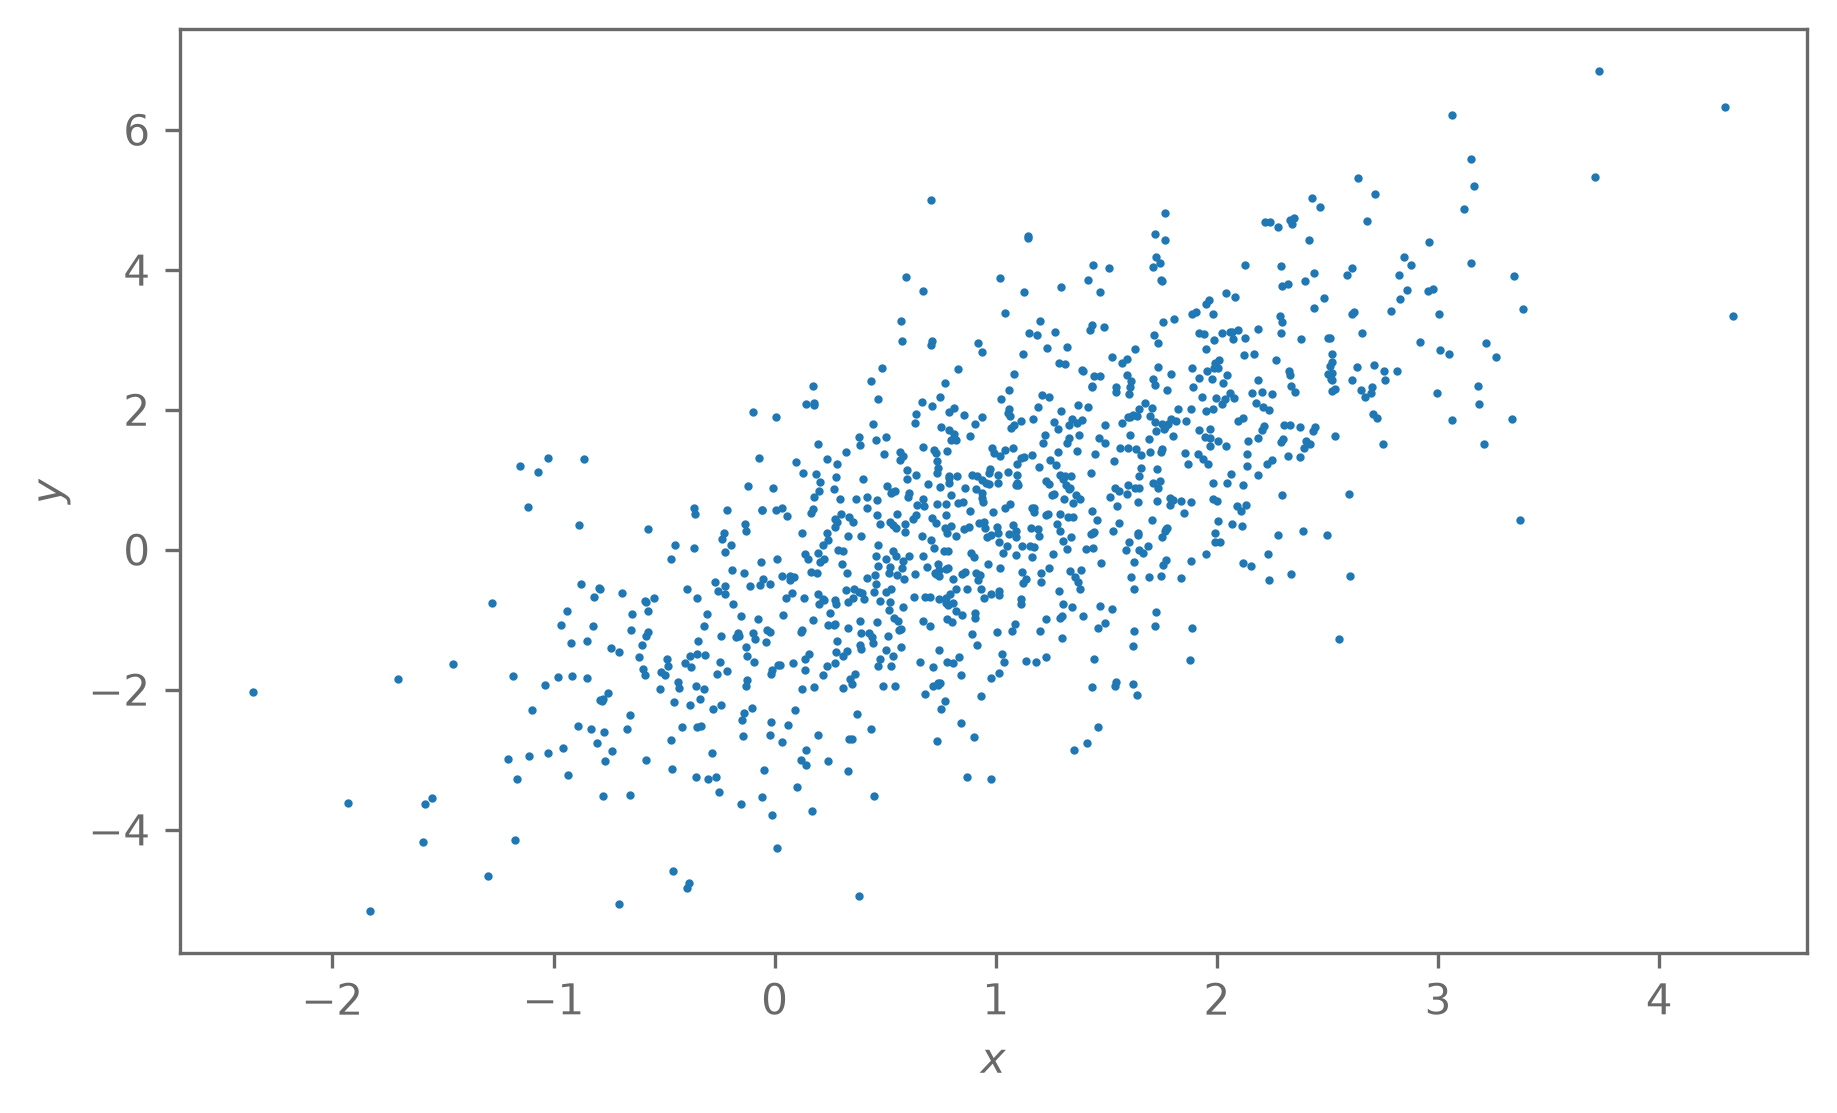

In [4]:
plt.scatter(*samples.T, s=1)
plt.ylabel("$y$")
plt.xlabel("$x$");

# N-dimensional Metropolis Hastings

In [5]:
def run_metropolis(x_start, log_posterior, proposal_cycle=None, proposal_weights=None, n_mcmc=1000):
    """
    x_start : np.ndarray
        starting point, (N, ) vector
    
    """
    if proposal_cycle is None:
        raise ValueError("must supply a proposal cycle")
    # weights for which proposals to use
    if proposal_weights is None:
        proposal_weights = np.ones(len(proposal_cycle)) / len(proposal_cycle)

    # keep track of samples, acceptances, and which proposals
    # are used
    samples = np.zeros((n_mcmc, x_start.size))
    acceptances = np.zeros(n_mcmc, dtype=bool)
    log_posterior_values = np.zeros(n_mcmc)
    proposals = np.zeros(n_mcmc, dtype=int)

    # update to current values
    x_current = np.array(x_start, copy=True)
    lp_current = log_posterior(x_current)

    assert np.isfinite(lp_current), "starting point must be within prior bounds and have finite posterior"
    
    for ii in tqdm(range(n_mcmc)):
        kk = np.random.choice(len(proposal_cycle), p=proposal_weights)
        proposals[ii] = kk
        # get proposal from q(x | y) and 
        # the ratio ln(q(y | x) / q(x | y))
        x_proposed, log_q_ratio = proposal_cycle[kk](x_current)

        # now calculate p(x)
        lp_proposed = log_posterior(x_proposed)

        # now alpha
        ln_alpha = min(lp_proposed - lp_current + log_q_ratio, np.log(1))

        # now accept
        if np.log(np.random.rand()) < ln_alpha:
            # update current value
            x_current = x_proposed
            lp_current = lp_proposed
            acceptances[ii] = True
        # else: don't update current value, stay at this point
        # so x_current and lp_current don't change
        samples[ii] = x_current
        log_posterior_values[ii] = lp_current
    return samples, acceptances, log_posterior_values, proposals

def prior_draw_proposal(x_current, minvals=None, maxvals=None):
    """
    return a draw from the prior. this doesn't actually
    depend on the current value so the ratio q(y | x) / q(x | y)
    is just 1. 
    """
    N_parameters = x_current.size
    return np.random.rand(N_parameters) * (maxvals - minvals) + minvals, np.log(1)

# range for the prior proposals and prior itself
# be careful here, you can easily cut off regions of
# non-zero likelihood, or hard boundaries
# in proposals can be bad because you can then never
# get to certain regions of parameter space. 
prior_minvals = -7 * np.ones(2)
prior_maxvals = 7 * np.ones(2)

uniform_prior_draw_2d = partial(prior_draw_proposal,minvals=prior_minvals, maxvals=prior_maxvals)

# Implement the prior
def uniform_nd_ln_prior(x, minvals=None, maxvals=None):
    assert len(x) == len(minvals) and len(x)==len(maxvals)
    ln_volume = np.sum(np.log(maxvals - minvals))
    if np.any(x < minvals) or np.any(x > maxvals):
        return -np.inf
    else:
        return -ln_volume

uniform_2d_ln_prior = partial(uniform_nd_ln_prior, minvals=prior_minvals, maxvals=prior_maxvals)


# unit variance, uncorrelated Gaussian
def log_posterior_unit_variance_zero_mean_gaussian(x):
    sigma = np.eye(x.size) #
    sigma_inv = np.linalg.inv(sigma)
    x = np.atleast_1d(x)
    sgn, two_pi_sigma_logdet = np.linalg.slogdet(2 * np.pi * sigma)
    assert sgn > 0, "covariance must be positive definite" # for a covariance matrix
    return -0.5 * (x.T @ sigma_inv @ x) - 0.5 * two_pi_sigma_logdet + uniform_2d_ln_prior(x)

# Our 2D Gaussian from the exercise statement
sigma_x = 1
sigma_y = 2
rho = 0.7

# Define mean and covariance
mean = np.array([1, 0.5])
cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])

# correlated Gaussian where the mean/correlation is set out beforehand
def log_posterior_correlated_offset_gaussian(mean, cov, ln_prior):
    # we're just going to draw samples from this
    # so we're not estimating the mu and sigma themselves
    # so we can precompute these things
    cov_inv = np.linalg.inv(cov)
    sgn, two_pi_sigma_logdet = np.linalg.slogdet(2 * np.pi * cov)
    
    # note this is a necessary but not sufficient condition for positive definiteness
    # we should also check the eigenvalues. or take a cholesky
    assert sgn > 0, "covariance must have positive determinant" 

    # now create a function that evaluates the posterior given a vector in our
    # ND space.
    def lp(x):
        return -0.5 * (x - mean).T @ cov_inv @ (x - mean) - 0.5 * two_pi_sigma_logdet + ln_prior(x)
    # pass the truth values too
    lp.mean = mean
    lp.cov = cov
    lp.cov_inv = cov_inv
    lp.twopi_cov_det = two_pi_sigma_logdet
    return lp # Return the function

# create our ND gaussian posterior from a mean, covariance, and prior. In this case
# we pass 2D vectors and functions that expect 2D vectors.
lp_corr = log_posterior_correlated_offset_gaussian(mean, cov, uniform_2d_ln_prior)

In [6]:
out = run_metropolis(np.array([0, 0]), lp_corr, proposal_cycle=[uniform_prior_draw_2d], n_mcmc=1_000_000)

100%|████████████████████████████████████████████████████████████████████████████| 1000000/1000000 [00:14<00:00, 69094.64it/s]


In [7]:
samples, acceptances, lps, props = out
# we have a pretty poor acceptance ratio. we could definitely use better proposals...
print('acceptance ratio', np.sum(acceptances) / np.size(acceptances) * 100) # very low!! Would be nice to have a better one. 

acceptance ratio 9.09


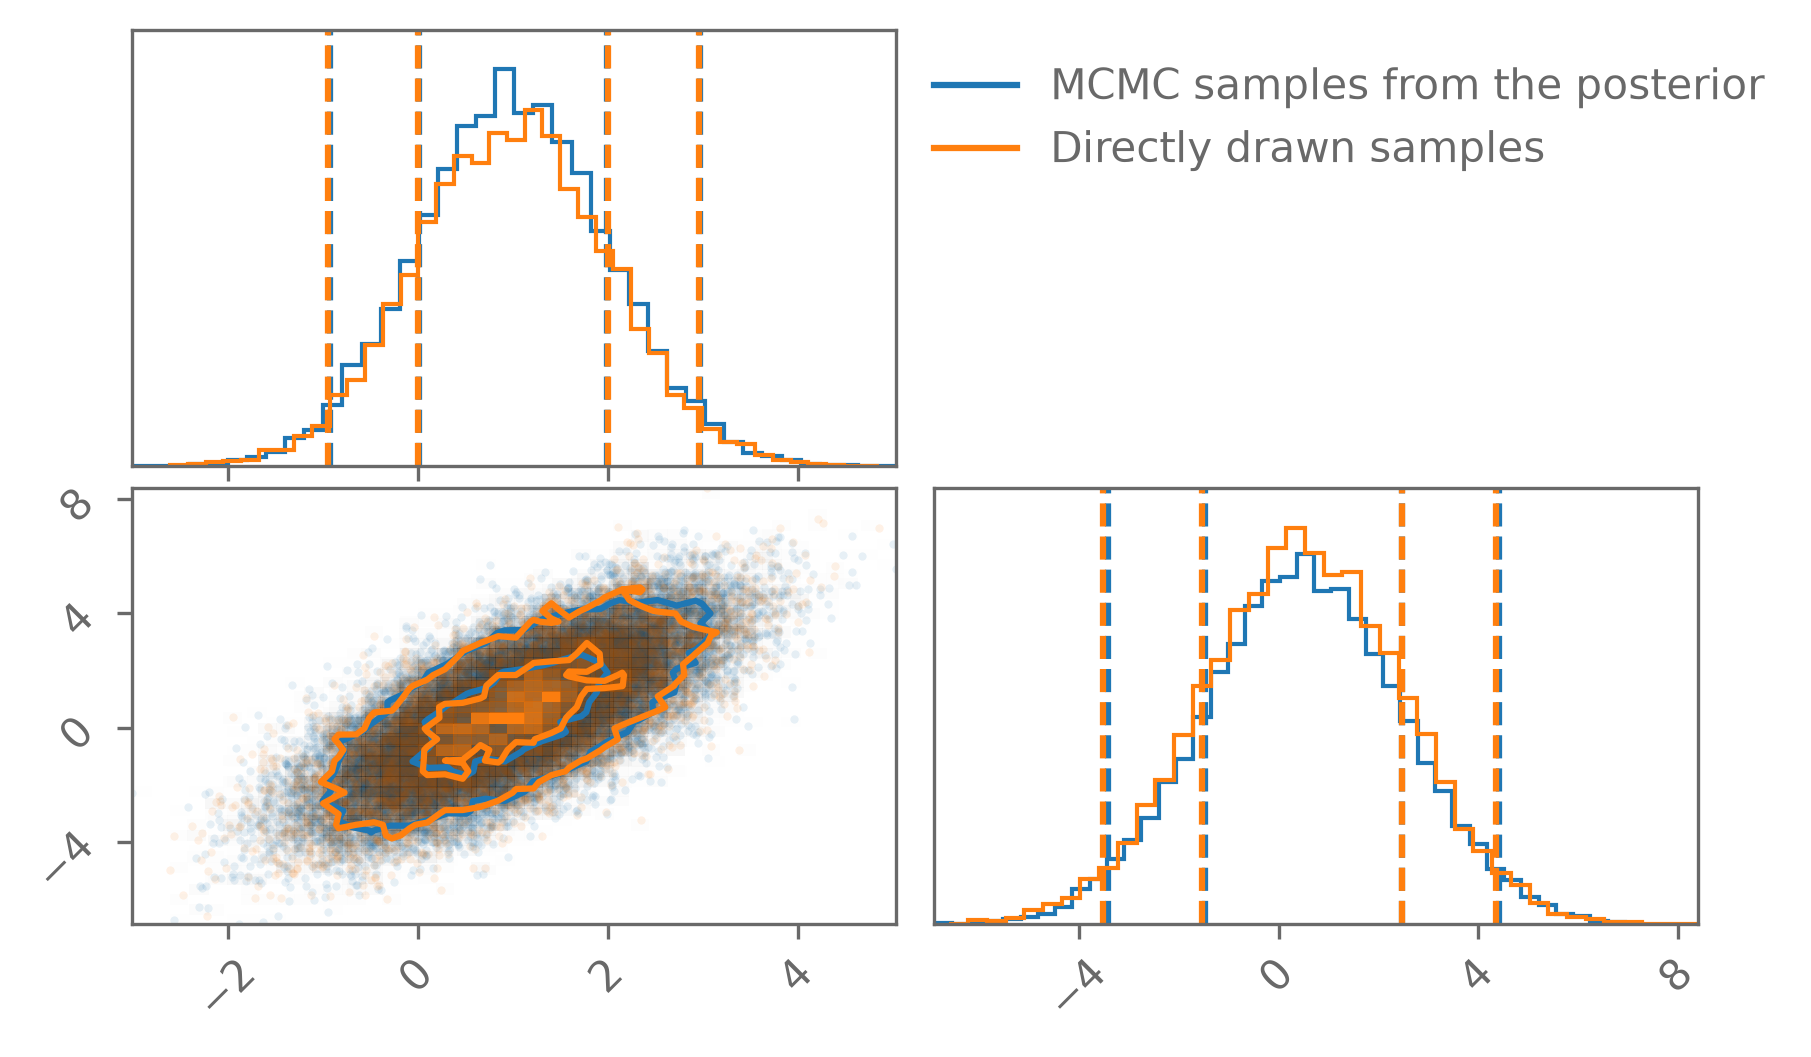

In [8]:
from corner import corner
mcmc_post = samples[3000::50] # thin and burn-in
fig = plt.figure()
fig = corner(
    mcmc_post,
    bins=40,
    color="C0",
    levels=1-np.exp(-0.5*np.array([1, 2])**2), # Credible contours corresponding
                                               # to 1 and 2 sigma in 2D
    quantiles=[0.025, 0.16, 0.84, 0.975],
    weights=np.full(len(mcmc_post), 1 / len(mcmc_post)),
    fig=fig
);
true_samples = np.random.multivariate_normal(mean, cov, size=10000)
corner(true_samples, bins=40, color='C1',
       levels=1-np.exp(-0.5*np.array([1, 2])**2), # Credible contours corresponding
                                               # to 1 and 2 sigma in 2D
       weights = np.full(len(true_samples), 1/len(true_samples)),
        quantiles=[0.025, 0.16, 0.84, 0.975],
        fig=fig)
fig.get_axes()[0].plot([], [], c="C0", label="MCMC samples from the posterior")
fig.get_axes()[0].plot([], [], c="C1", label="Directly drawn samples")
fig.get_axes()[0].legend(loc=2, bbox_to_anchor=(1, 1))
plt.show()

## Alternate proposal

Now let's try two proposals. First, a generic 2D uncorrelated Gaussian that is just wider than the actual distribution we want to sample. It doesn't depend on where we are.
Second, a proposal that places a Gaussian around the current point, which will now require a non-trivial proposal ratio.

In [9]:
def proposal_generic_gaussian(x):
    return np.random.multivariate_normal(np.zeros(len(x)), 25 * np.eye(len(x))), np.log(1) # 9 = 3^2 so a standard deviation of 3 in each uncorrelated direction

def current_value_centered_gaussian(x):
    x_centered_normal = scipy.stats.multivariate_normal(mean=x, cov=np.eye(len(x)))
    x_prime = x_centered_normal.rvs()
    x_prime_centered_normal = scipy.stats.multivariate_normal(mean=x_prime, cov=np.eye(len(x)))
    ln_q_x_given_xprime = x_prime_centered_normal.logpdf(x)
    ln_q_x_prime_given_x = x_centered_normal.logpdf(x_prime)
    return x_prime, ln_q_x_given_xprime - ln_q_x_prime_given_x

100%|██████████████████████████████████████████████████████████████████████████████| 100000/100000 [00:03<00:00, 28807.62it/s]


acceptance ratio generic gaussian 9.392


100%|███████████████████████████████████████████████████████████████████████████████| 100000/100000 [00:12<00:00, 7961.54it/s]


acceptance ratio centered gaussian 54.647999999999996


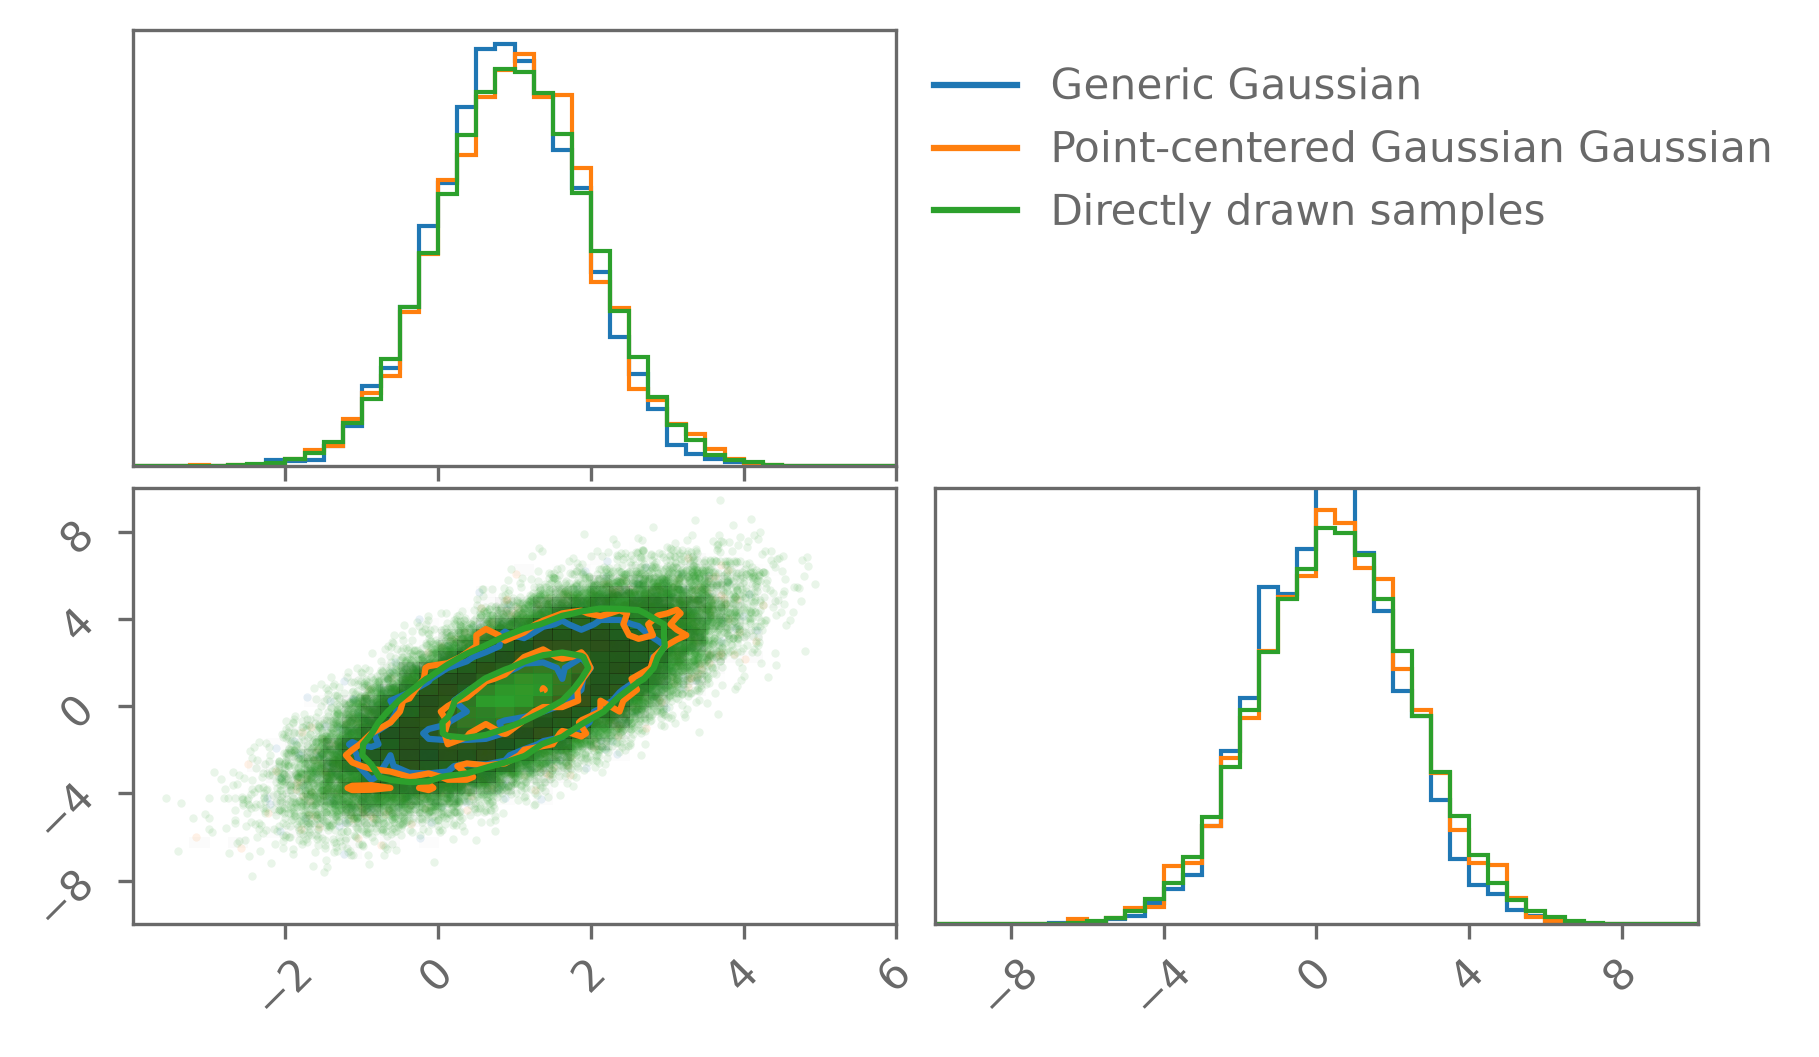

In [10]:
out_generic_gaussian = run_metropolis(np.array([0, 0]), lp_corr, proposal_cycle=[proposal_generic_gaussian], n_mcmc=100_000)
samples, acceptances, lps, props = out_generic_gaussian

rng = [(-4, 6), (-10, 10)]

# we have a pretty poor acceptance ratio. we could definitely use better proposals...
print('acceptance ratio generic gaussian', np.sum(acceptances) / np.size(acceptances) * 100) # very low!! Would be nice to have a better one. 
mcmc_post = samples[3000::30]
fig = plt.figure()
fig = corner(
    mcmc_post,
    bins=40,
    color="C0",
    levels=1-np.exp(-0.5*np.array([1, 2])**2), # Credible contours corresponding
                                               # to 1 and 2 sigma in 2D
    range=rng,
    weights=np.full(len(mcmc_post), 1 / len(mcmc_post)),
    fig=fig
);


out_generic_gaussian = run_metropolis(np.array([0, 0]), lp_corr, proposal_cycle=[current_value_centered_gaussian], n_mcmc=100_000)
samples, acceptances, lps, props = out_generic_gaussian
# we have a pretty poor acceptance ratio. we could definitely use better proposals...
print('acceptance ratio centered gaussian', np.sum(acceptances) / np.size(acceptances) * 100) # very low!! Would be nice to have a better one. 
mcmc_post = samples[3000::30]
fig = corner(
    mcmc_post,
    bins=40,
    color="C1",
    range=rng,
    levels=1-np.exp(-0.5*np.array([1, 2])**2), # Credible contours corresponding
                                               # to 1 and 2 sigma in 2D
    weights=np.full(len(mcmc_post), 1 / len(mcmc_post)),
    fig=fig
);

true_samples = np.random.multivariate_normal(mean, cov, size=100000)
corner(true_samples, bins=40, color='C2',
       levels=1-np.exp(-0.5*np.array([1, 2])**2), # Credible contours corresponding
                                               # to 1 and 2 sigma in 2D
       weights = np.full(len(true_samples), 1/len(true_samples)),
       range=rng,
        fig=fig)
fig.get_axes()[0].plot([], [], c="C0", label="Generic Gaussian")
fig.get_axes()[0].plot([], [], c="C1", label="Point-centered Gaussian Gaussian")
fig.get_axes()[0].plot([], [], c="C2", label="Directly drawn samples")
fig.get_axes()[0].legend(loc=2, bbox_to_anchor=(1, 1))
plt.show()

# Showing detailed balance for Metropolis-Hastings

We want to show the condition for detailed balance

$$T(x \mid y) \,p(y) = T(y \mid x) \,p(x)$$

given that, from our rules for M.H. steps we have:

$$T(x \mid y) = q(x \mid y) \,\min(1, \alpha)$$

where 

$$\alpha \equiv \frac{q(y \mid x)\, p(x)}{q(x \mid y)\,p(y)}$$

## Proof

We start from the LHS and work to the right:
\begin{align}
T(x \mid y)\,p(y) &= q(x \mid y)\, p(y) \min\left(1,\frac{q(y \mid x) \,p(x)}{q(x \mid y)\,p(y)}\right)\,,\\
&=\min\left(q(x \mid y) \, p(y), q(y \mid x)\,p(x)\right)\,,\\
&=q(y \mid x)\,p(x)\min\left(\frac{q(x \mid y)\, p(y)}{q(y \mid x)\,p(x)}, 1\right)\,,\\
&=q(y \mid x)\,p(x) \min\left(\alpha^{-1}, 1\right)\,,\\
&=T(y \mid x)\,p(x)\checkmark\,.
\end{align}

Note that the last line completes the proof because the acceptance ratio $\alpha$ for moving from $y\rightarrow x$ is the inverse of the ratio for moving from $x \rightarrow y$